# Лабораторная работа №3

## Задание

1. Примените методы снижения размерности (до двумерного представления
n_components=2) перечисленные ниже для данных находящихся пo
[ссылке](https://drive.google.com/file/d/1LBDnhITL0Wqwp5G6M6IBI-SSz8BIoNec/view). Здесь - метка (учитель) является столбец / атрибут - `outcome`. Предоставьте результаты, используя следующие ядерные функции:
- PCA
- LDA
- TruncatedSVD
- Kernel PCA (перебрав все ядерные функции - ('linear', 'poly', 'rbf', sigmoid',
'cosine', 'precomputed')

## Загрузка данных

In [44]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA, TruncatedSVD, KernelPCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

In [45]:
LOCAL_PATH = "data/diabetes.csv"
GITHUB_RAW_URL = "https://raw.githubusercontent.com/lufikow/intro-ai/refs/heads/main/data/diabetes.csv"

if os.path.exists(LOCAL_PATH):
    df = pd.read_csv(LOCAL_PATH)
else:
    df = pd.read_csv(GITHUB_RAW_URL)

In [46]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [48]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [49]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

## Preprocessing

In [50]:
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[zero_cols] = df[zero_cols].replace(0, np.nan)

X = df.drop(columns='Outcome').values
y = df['Outcome'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

imputer = SimpleImputer(strategy='median').fit(X_train)
scaler = StandardScaler().fit(imputer.transform(X_train))
X_train_sc = scaler.transform(imputer.transform(X_train))
X_test_sc = scaler.transform(imputer.transform(X_test))

In [51]:
def evaluate(name, Z_train, Z_test):
    clf = LogisticRegression(max_iter=1000, class_weight='balanced').fit(Z_train, y_train)
    pred = clf.predict(Z_test)
    proba = clf.predict_proba(Z_test)[:, 1]
    results.append({
        'Method': name,
        'Dims': Z_train.shape[1],
        'Accuracy': accuracy_score(y_test, pred),
        'ROC AUC': roc_auc_score(y_test, proba)
    })
    embeds[name] = (Z_train, Z_test)

results, embeds = [], {}

## Метод PCA

In [52]:
pca = PCA(n_components=2, random_state=42).fit(X_train_sc)
evaluate('PCA', pca.transform(X_train_sc), pca.transform(X_test_sc))

## Метод LDA

In [53]:
lda = LinearDiscriminantAnalysis(n_components=1).fit(X_train_sc, y_train)
evaluate('LDA', lda.transform(X_train_sc), lda.transform(X_test_sc))

## Метод TruncatedSVD

In [54]:
svd = TruncatedSVD(n_components=2, random_state=42).fit(X_train_sc)
evaluate('TruncatedSVD', svd.transform(X_train_sc), svd.transform(X_test_sc))

## Метод Kernel PCA

In [55]:
for k in ['linear', 'poly', 'rbf', 'sigmoid', 'cosine']:
    kpca = KernelPCA(n_components=2, kernel=k, random_state=42)
    evaluate(f'KernelPCA ({k})', kpca.fit_transform(X_train_sc), kpca.transform(X_test_sc))

###  Ядерная функция `precomputed`

In [56]:
K_train = X_train_sc @ X_train_sc.T
K_test = X_test_sc @ X_train_sc.T
kpca_pre = KernelPCA(n_components=2, kernel='precomputed')
evaluate('Kernel PCA (precomputed linear)', kpca_pre.fit_transform(K_train), kpca_pre.transform(K_test))

## Results

In [57]:
res = pd.DataFrame(results)
print(res.round(3))

                            Method  Dims  Accuracy  ROC AUC
0                              PCA     2     0.695    0.759
1                              LDA     1     0.727    0.813
2                     TruncatedSVD     2     0.695    0.759
3               KernelPCA (linear)     2     0.695    0.759
4                 KernelPCA (poly)     2     0.662    0.716
5                  KernelPCA (rbf)     2     0.643    0.734
6              KernelPCA (sigmoid)     2     0.688    0.759
7               KernelPCA (cosine)     2     0.669    0.751
8  Kernel PCA (precomputed linear)     2     0.695    0.759


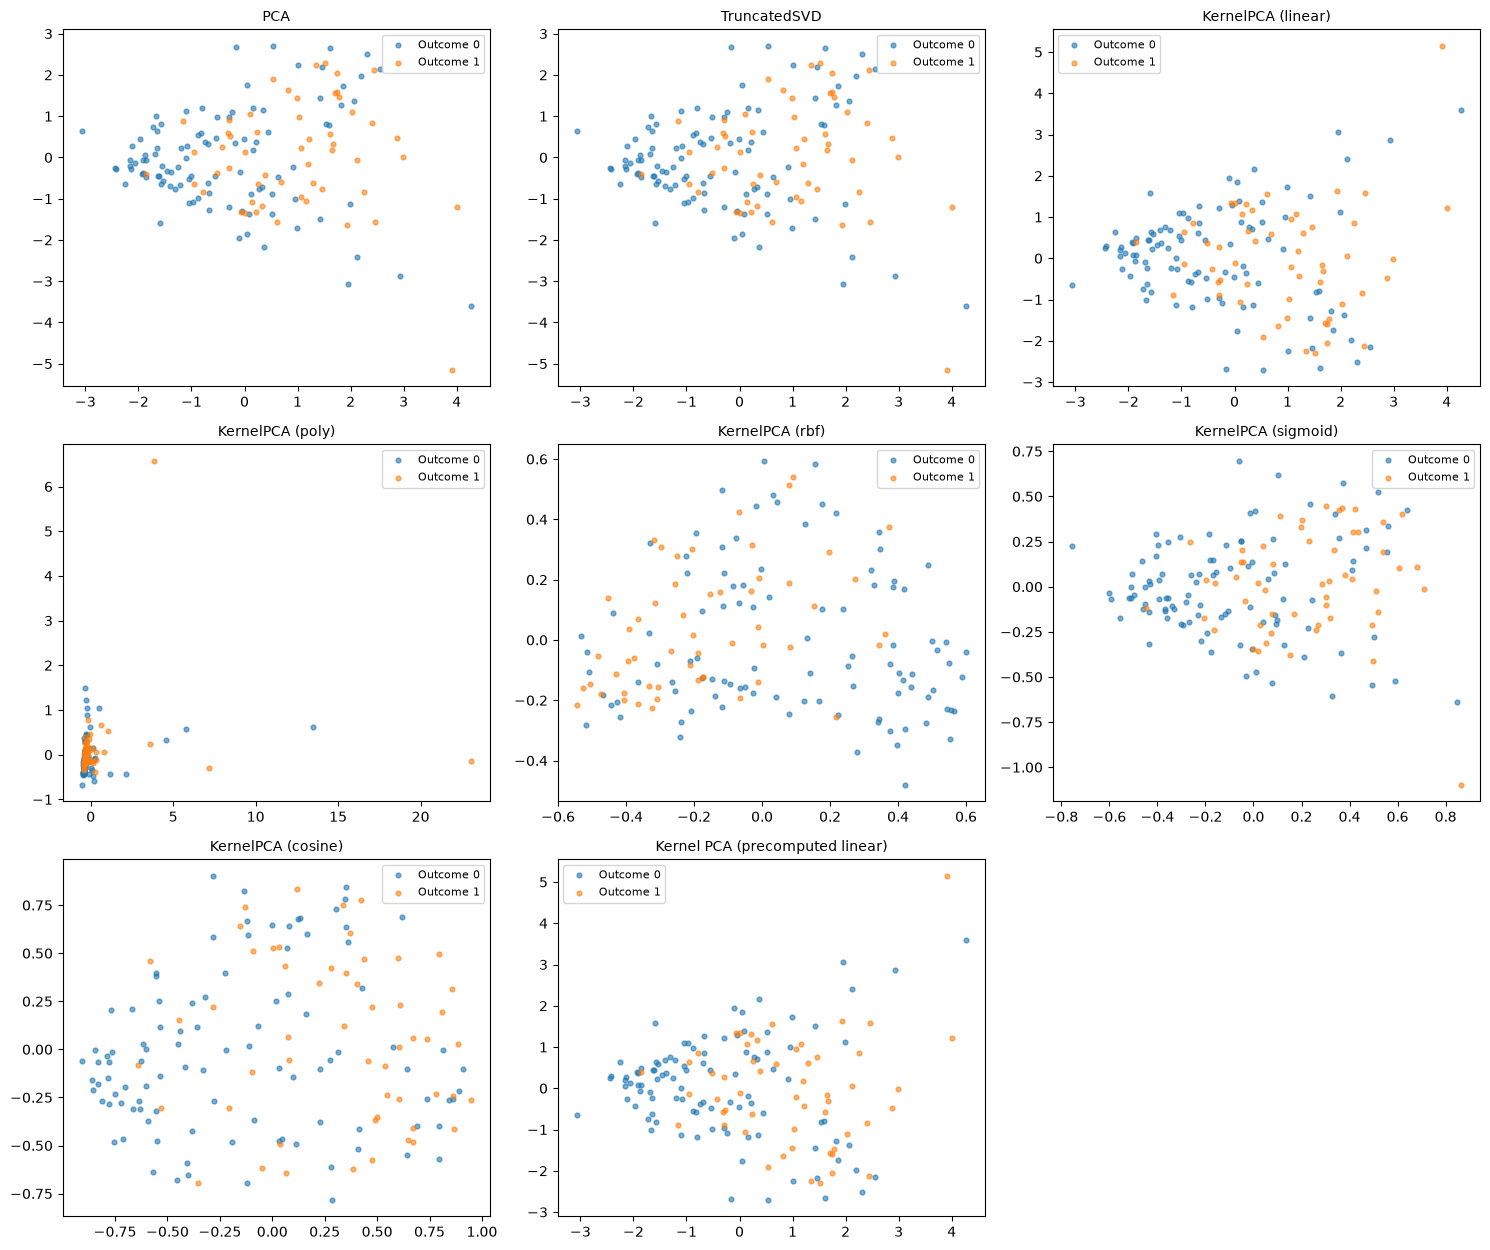

In [58]:
names = [n for n in embeds if embeds[n][0].shape[1] == 2]
cols_n = 3
rows_n = int(np.ceil(len(names) / cols_n))
fig, axes = plt.subplots(rows_n, cols_n, figsize=(5 * cols_n, 4.2 * rows_n))
axes = np.atleast_1d(axes).ravel()
for ax, name in zip(axes, names):
    Z = embeds[name][1]
    ax.scatter(Z[y_test == 0, 0], Z[y_test == 0, 1], s=12, alpha=0.6, label="Outcome 0")
    ax.scatter(Z[y_test == 1, 0], Z[y_test == 1, 1], s=12, alpha=0.6, label="Outcome 1")
    ax.set_title(name, fontsize=10)
    ax.legend(fontsize=8)
for ax in axes[len(names):]:
    ax.axis("off")
fig.tight_layout()

## Вывод

* LDA в 2D невозможна. Для бинарного признака число дискриминантных компонент не может превышать 1.
* PCA и TruncatedSVD дали одинаковый результат. Так как данные стандартизированы, они имеют одно центрование, а именно оно и отличает эти два метода.
* Kernel PCA с линейным ядром и с precomputed дали одинаковый результат. Под капотом одна математика.
* Нелинейные ядра хуже линейных. Poly, rbf и cosine ухудшают разделение, потому что нелинейная проекция без учителя выбирает направления максимальной дисперсии, а не те, что различают классы.
* **Без учителя 2D-проекция теряет много информации.** Поэтому методы без учителя уступают LDA, которая знает метку.